# Experiment 17 — Final Model Selection & Robustness

## 1. Executive Summary & Experimental Objectives
Welcome to **Experiment 17** of the AI Lab curriculum! Across previous phases, we developed and trained multiple candidate model families:
- **Track A (MNIST Digit Recognition):** Baseline Production CNN (`cnn_mnist.pt`) vs. Augmented CNN (`cnn_mnist_augmented.pt`).
- **Track B (CIFAR-10 Transfer Learning):** From-scratch CNN vs. Frozen ResNet-18 vs. Fine-tuned ResNet-18.

### Core Experimental Questions:
1. **Track A (Production Decision):** Does training with data augmentation provide general out-of-distribution robustness against Gaussian noise, blur, occlusion/cutout, and contrast shifts, or does the original baseline production model remain superior?
2. **Track B (Educational Transfer Learning):** How do the historical CIFAR-10 transfer learning results compare, and why are active perturbation tests formally documented as omitted?

### Ground Rules:
- **Zero Retraining:** Both models are strictly evaluated in inference mode (`model.eval()`).
- **Identical Controls:** Identical test instances, identical random perturbation seeds, identical hardware.
- **Production Safety:** `backend/models/cnn_mnist.pt` remains completely untouched.

In [1]:
import time
import math
import hashlib
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from PIL import Image

import sys
sys.path.insert(0, str(Path('..').resolve() / 'backend'))
if not (Path('..').resolve() / 'backend').exists():
    sys.path.insert(0, 'backend')
from src.model import HandwrittenDigitCNN
from src.inference import preprocess_image

# Controlled Seed & Device
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device('cpu')

# Resolve model paths
BASE_DIR = Path('..').resolve() if (Path('..') / 'backend').exists() else Path('.').resolve()
MODEL_A_PATH = BASE_DIR / 'backend' / 'models' / 'cnn_mnist.pt'
MODEL_B_PATH = BASE_DIR / 'backend' / 'models' / 'cnn_mnist_augmented.pt'

# Verify Model A SHA-256
with open(MODEL_A_PATH, 'rb') as f:
    sha_a = hashlib.sha256(f.read()).hexdigest()

# Instantiate and load models
m_a = HandwrittenDigitCNN().to(DEVICE)
m_a.load_state_dict(torch.load(MODEL_A_PATH, map_location=DEVICE, weights_only=True))
m_a.eval()

m_b = HandwrittenDigitCNN().to(DEVICE)
m_b.load_state_dict(torch.load(MODEL_B_PATH, map_location=DEVICE, weights_only=True))
m_b.eval()

params_a = sum(p.numel() for p in m_a.parameters())
params_b = sum(p.numel() for p in m_b.parameters())

print('=' * 65)
print('EXPERIMENT 17: MODEL CHECKPOINT PREFLIGHT VERIFICATION')
print('=' * 65)
print(f'Model A (Production Baseline): {MODEL_A_PATH.name}')
print(f'  SHA-256 Hash:                {sha_a}')
print(f'  Total Parameters:            {params_a:,} (Trainable: {params_a:,}, Frozen: 0)')
print(f'Model B (Augmented CNN):       {MODEL_B_PATH.name}')
print(f'  Total Parameters:            {params_b:,} (Trainable: {params_b:,}, Frozen: 0)')
print(f'Evaluation Device:             {DEVICE} (Inference mode, zero retraining)')
print('=' * 65)

EXPERIMENT 17: MODEL CHECKPOINT PREFLIGHT VERIFICATION
Model A (Production Baseline): cnn_mnist.pt
  SHA-256 Hash:                e7bd9dbc143c566481c2944b699b9b56b43167a0c3ad0018afa5e8cd17bcf87a
  Total Parameters:            421,642 (Trainable: 421,642, Frozen: 0)
Model B (Augmented CNN):       cnn_mnist_augmented.pt
  Total Parameters:            421,642 (Trainable: 421,642, Frozen: 0)
Evaluation Device:             cpu (Inference mode, zero retraining)


---
## 2. Track A — Step 1: Clean MNIST Test Benchmark
We evaluate both models on the complete 10,000 canonical test images (`MNIST t10k`).
Neither model receives any distortion or perturbation in this baseline pass.

In [1]:
# Load canonical MNIST test dataset
RAW_DATA_PATH = BASE_DIR / 'backend' / 'data' / 'raw'
test_dataset = torchvision.datasets.MNIST(
    root=RAW_DATA_PATH,
    train=False,
    download=False,
    transform=transforms.ToTensor()
)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=500, shuffle=False)

def evaluate_on_batches(model, corruption_fn=None, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    correct = 0
    total = 0
    confs = []
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if corruption_fn is not None:
                x = corruption_fn(x)
            logits = model(x)
            probs = F.softmax(logits, dim=1)
            conf, pred = torch.max(probs, dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            confs.extend(conf.cpu().numpy())
    acc = correct / total
    err = total - correct
    mean_conf = float(np.mean(confs))
    return acc, err, mean_conf

acc_clean_a, err_clean_a, conf_clean_a = evaluate_on_batches(m_a)
acc_clean_b, err_clean_b, conf_clean_b = evaluate_on_batches(m_b)

print('=' * 65)
print('TRACK A: CLEAN MNIST BENCHMARK (10,000 SAMPLES)')
print('=' * 65)
print(f'Model A (Production): Accuracy = {acc_clean_a*100:.2f}% | Errors = {err_clean_a} | Mean Conf = {conf_clean_a*100:.2f}%')
print(f'Model B (Augmented):  Accuracy = {acc_clean_b*100:.2f}% | Errors = {err_clean_b} | Mean Conf = {conf_clean_b*100:.2f}%')
print('=' * 65)

TRACK A: CLEAN MNIST BENCHMARK (10,000 SAMPLES)
Model A (Production): Accuracy = 99.07% | Errors = 93 | Mean Conf = 99.30%
Model B (Augmented):  Accuracy = 98.83% | Errors = 117 | Mean Conf = 98.77%


---
## 3. Track A — Step 2: Gaussian Noise Perturbation Suite
We inject additive Gaussian noise with standard deviation $\sigma \in \{0.05, 0.10, 0.20, 0.30\}$, clamping intensities to $[0, 1]$:
$$x_{noisy} = \text{clamp}(x + \mathcal{N}(0, \sigma^2), 0.0, 1.0)$$
This simulates sensor noise, thermal camera artifacts, and high-frequency background grain.

In [1]:
noise_sigmas = [0.05, 0.10, 0.20, 0.30]
noise_results_a = []
noise_results_b = []

print('=== GAUSSIAN NOISE STRESS TEST ===')
for sig in noise_sigmas:
    def add_noise(x, s=sig):
        noise = torch.randn_like(x) * s
        return torch.clamp(x + noise, 0.0, 1.0)
    res_a = evaluate_on_batches(m_a, add_noise)
    res_b = evaluate_on_batches(m_b, add_noise)
    noise_results_a.append(res_a)
    noise_results_b.append(res_b)
    print(f'Sigma={sig:.2f} | Model A: Acc={res_a[0]*100:.2f}% (Err={res_a[1]:4d}, Conf={res_a[2]*100:.2f}%) | Model B: Acc={res_b[0]*100:.2f}% (Err={res_b[1]:4d}, Conf={res_b[2]*100:.2f}%)')

=== GAUSSIAN NOISE STRESS TEST ===
Sigma=0.05 | Model A: Acc=99.07% (Err=  93, Conf=99.24%) | Model B: Acc=98.84% (Err= 116, Conf=98.63%)
Sigma=0.10 | Model A: Acc=99.02% (Err=  98, Conf=99.14%) | Model B: Acc=98.87% (Err= 113, Conf=98.26%)
Sigma=0.20 | Model A: Acc=98.79% (Err= 121, Conf=98.51%) | Model B: Acc=96.98% (Err= 302, Conf=93.85%)
Sigma=0.30 | Model A: Acc=97.66% (Err= 234, Conf=95.23%) | Model B: Acc=73.75% (Err=2625, Conf=82.72%)


---
## 4. Track A — Step 3: Defocus Blur Perturbation Suite
We apply 2D Gaussian blur kernels with radius $\sigma_{blur} \in \{0.5, 1.0, 1.5, 2.0\}$ (kernel size 5).
This models optical defocus, rapid pen strokes, and interpolation blur from downsampling.

In [1]:
blur_sigmas = [0.5, 1.0, 1.5, 2.0]
blur_results_a = []
blur_results_b = []

print('=== DEFOCUS BLUR STRESS TEST ===')
for sig in blur_sigmas:
    blur_transform = transforms.GaussianBlur(kernel_size=5, sigma=sig)
    def apply_blur(x, bt=blur_transform):
        return bt(x)
    res_a = evaluate_on_batches(m_a, apply_blur)
    res_b = evaluate_on_batches(m_b, apply_blur)
    blur_results_a.append(res_a)
    blur_results_b.append(res_b)
    print(f'Sigma={sig:.1f} | Model A: Acc={res_a[0]*100:.2f}% (Err={res_a[1]:4d}, Conf={res_a[2]*100:.2f}%) | Model B: Acc={res_b[0]*100:.2f}% (Err={res_b[1]:4d}, Conf={res_b[2]*100:.2f}%)')

=== DEFOCUS BLUR STRESS TEST ===
Sigma=0.5 | Model A: Acc=98.97% (Err= 103, Conf=99.07%) | Model B: Acc=98.67% (Err= 133, Conf=98.20%)
Sigma=1.0 | Model A: Acc=98.02% (Err= 198, Conf=96.79%) | Model B: Acc=96.39% (Err= 361, Conf=92.61%)
Sigma=1.5 | Model A: Acc=96.68% (Err= 332, Conf=92.05%) | Model B: Acc=92.77% (Err= 723, Conf=83.00%)
Sigma=2.0 | Model A: Acc=95.52% (Err= 448, Conf=88.18%) | Model B: Acc=90.08% (Err= 992, Conf=77.03%)


---
## 5. Track A — Step 4: Random Occlusion / Cutout Suite
We evaluate random square patch occlusions of $15\%$ ($11 \times 11$), $30\%$ ($15 \times 15$), and $50\%$ ($20 \times 20$) area.
This models missing stroke segments, pen skips, and partial finger/stylus occlusions.

In [1]:
cutout_configs = [(15, 11), (30, 15), (50, 20)]
cutout_results_a = []
cutout_results_b = []

print('=== RANDOM OCCLUSION / CUTOUT STRESS TEST ===')
for pct, patch_sz in cutout_configs:
    def apply_cutout(x, sz=patch_sz):
        B, C, H, W = x.shape
        x_out = x.clone()
        for i in range(B):
            top = np.random.randint(0, H - sz + 1)
            left = np.random.randint(0, W - sz + 1)
            x_out[i, :, top:top+sz, left:left+sz] = 0.0
        return x_out
    res_a = evaluate_on_batches(m_a, apply_cutout)
    res_b = evaluate_on_batches(m_b, apply_cutout)
    cutout_results_a.append(res_a)
    cutout_results_b.append(res_b)
    print(f'Cutout {pct:2d}% ({patch_sz}x{patch_sz}) | Model A: Acc={res_a[0]*100:.2f}% (Err={res_a[1]:4d}, Conf={res_a[2]*100:.2f}%) | Model B: Acc={res_b[0]*100:.2f}% (Err={res_b[1]:4d}, Conf={res_b[2]*100:.2f}%)')

=== RANDOM OCCLUSION / CUTOUT STRESS TEST ===
Cutout 15% (11x11) | Model A: Acc=80.61% (Err=1939, Conf=91.53%) | Model B: Acc=71.88% (Err=2812, Conf=88.30%)
Cutout 30% (15x15) | Model A: Acc=55.60% (Err=4440, Conf=78.34%) | Model B: Acc=41.79% (Err=5821, Conf=76.54%)
Cutout 50% (20x20) | Model A: Acc=23.57% (Err=7643, Conf=51.90%) | Model B: Acc=19.67% (Err=8033, Conf=54.71%)


---
## 6. Track A — Step 5: Contrast Scaling Suite
We scale pixel stroke intensities by factors of $\times 0.50, \times 0.75, \times 1.25, \times 1.50$, clamped to $[0, 1]$.
This models faint pencil strokes (dimming) vs heavy saturated ink markers (over-saturation).

In [1]:
contrast_factors = [0.5, 0.75, 1.25, 1.5]
contrast_results_a = []
contrast_results_b = []

print('=== CONTRAST SCALING STRESS TEST ===')
for factor in contrast_factors:
    def apply_contrast(x, c=factor):
        return torch.clamp(x * c, 0.0, 1.0)
    res_a = evaluate_on_batches(m_a, apply_contrast)
    res_b = evaluate_on_batches(m_b, apply_contrast)
    contrast_results_a.append(res_a)
    contrast_results_b.append(res_b)
    print(f'Contrast x{factor:.2f} | Model A: Acc={res_a[0]*100:.2f}% (Err={res_a[1]:4d}, Conf={res_a[2]*100:.2f}%) | Model B: Acc={res_b[0]*100:.2f}% (Err={res_b[1]:4d}, Conf={res_b[2]*100:.2f}%)')

=== CONTRAST SCALING STRESS TEST ===
Contrast x0.50 | Model A: Acc=98.68% (Err= 132, Conf=93.78%) | Model B: Acc=96.58% (Err= 342, Conf=86.67%)
Contrast x0.75 | Model A: Acc=99.01% (Err=  99, Conf=98.60%) | Model B: Acc=98.49% (Err= 151, Conf=97.25%)
Contrast x1.25 | Model A: Acc=99.01% (Err=  99, Conf=99.35%) | Model B: Acc=98.82% (Err= 118, Conf=98.84%)
Contrast x1.50 | Model A: Acc=99.02% (Err=  98, Conf=99.33%) | Model B: Acc=98.76% (Err= 124, Conf=98.79%)


---
## 7. Track A — Step 6: Real-World 35-Sample Handwriting Benchmark
We evaluate both models on the 35 freehand drawings collected in Phase 10 ([`backend/data/real_world/raw/`](../backend/data/real_world/raw/)).
Both models receive inputs preprocessed identically using Phase 10's center-of-mass and aspect-ratio normalization pipeline.

In [1]:
raw_dir = BASE_DIR / 'backend' / 'data' / 'real_world' / 'raw'
real_world_files = sorted(list(raw_dir.glob('*.png')))

rw_correct_a = 0
rw_correct_b = 0
rw_confs_a = []
rw_confs_b = []

for fpath in real_world_files:
    true_label = int(fpath.stem.split('_')[1])
    img = Image.open(fpath)
    tensor = preprocess_image(img).to(DEVICE)
    with torch.no_grad():
        p_a = F.softmax(m_a(tensor), dim=1)
        c_a, pred_a = torch.max(p_a, dim=1)
        p_b = F.softmax(m_b(tensor), dim=1)
        c_b, pred_b = torch.max(p_b, dim=1)
        if pred_a.item() == true_label: rw_correct_a += 1
        if pred_b.item() == true_label: rw_correct_b += 1
        rw_confs_a.append(c_a.item())
        rw_confs_b.append(c_b.item())

rw_acc_a = rw_correct_a / len(real_world_files)
rw_acc_b = rw_correct_b / len(real_world_files)
rw_mean_conf_a = float(np.mean(rw_confs_a))
rw_mean_conf_b = float(np.mean(rw_confs_b))

print('=' * 65)
print('REAL-WORLD HANDWRITING BENCHMARK (35 SAMPLES)')
print('=' * 65)
print(f'Model A (Production Baseline): Accuracy = {rw_acc_a*100:.1f}% ({len(real_world_files)-rw_correct_a} errors) | Mean Conf = {rw_mean_conf_a*100:.2f}%')
print(f'Model B (Augmented CNN):       Accuracy = {rw_acc_b*100:.1f}% ({len(real_world_files)-rw_correct_b} errors) | Mean Conf = {rw_mean_conf_b*100:.2f}%')
print('=' * 65)

REAL-WORLD HANDWRITING BENCHMARK (35 SAMPLES)
Model A (Production Baseline): Accuracy = 100.0% (0 errors) | Mean Conf = 98.48%
Model B (Augmented CNN):       Accuracy = 100.0% (0 errors) | Mean Conf = 95.64%


---
## 8. Track A — Step 7: Inference Latency & Throughput Benchmark
We profile single-image CPU inference with 1,000 warm-up runs followed by 2,000 timed runs, extracting P50, P95, and P99 percentiles.
Throughput is measured across 100 batches of 64 images on CPU.

In [1]:
single_input = torch.randn(1, 1, 28, 28, device=DEVICE)

def benchmark_latency(model, num_warmup=1000, num_timed=2000):
    with torch.no_grad():
        for _ in range(num_warmup):
            _ = model(single_input)
        times_ms = []
        for _ in range(num_timed):
            t0 = time.perf_counter()
            _ = model(single_input)
            t1 = time.perf_counter()
            times_ms.append((t1 - t0) * 1000.0)
    return np.percentile(times_ms, 50), np.percentile(times_ms, 95), np.percentile(times_ms, 99), np.mean(times_ms)

lat_a = benchmark_latency(m_a)
lat_b = benchmark_latency(m_b)

batch_input = torch.randn(64, 1, 28, 28, device=DEVICE)
def benchmark_throughput(model, num_batches=100):
    with torch.no_grad():
        for _ in range(20): _ = model(batch_input)
        t0 = time.perf_counter()
        for _ in range(num_batches): _ = model(batch_input)
        t1 = time.perf_counter()
    return (num_batches * 64) / (t1 - t0)

tp_a = benchmark_throughput(m_a)
tp_b = benchmark_throughput(m_b)

print('=' * 65)
print('INFERENCE LATENCY & THROUGHPUT BENCHMARK (CPU)')
print('=' * 65)
print(f'Model A (Production): P50 = {lat_a[0]:.3f} ms | P95 = {lat_a[1]:.3f} ms | P99 = {lat_a[2]:.3f} ms | Throughput = {tp_a:.1f} samples/s')
print(f'Model B (Augmented):  P50 = {lat_b[0]:.3f} ms | P95 = {lat_b[1]:.3f} ms | P99 = {lat_b[2]:.3f} ms | Throughput = {tp_b:.1f} samples/s')
print('=' * 65)

INFERENCE LATENCY & THROUGHPUT BENCHMARK (CPU)
Model A (Production): P50 = 0.376 ms | P95 = 0.721 ms | P99 = 1.857 ms | Throughput = 7999.3 samples/s
Model B (Augmented):  P50 = 0.374 ms | P95 = 0.694 ms | P99 = 1.804 ms | Throughput = 7262.2 samples/s


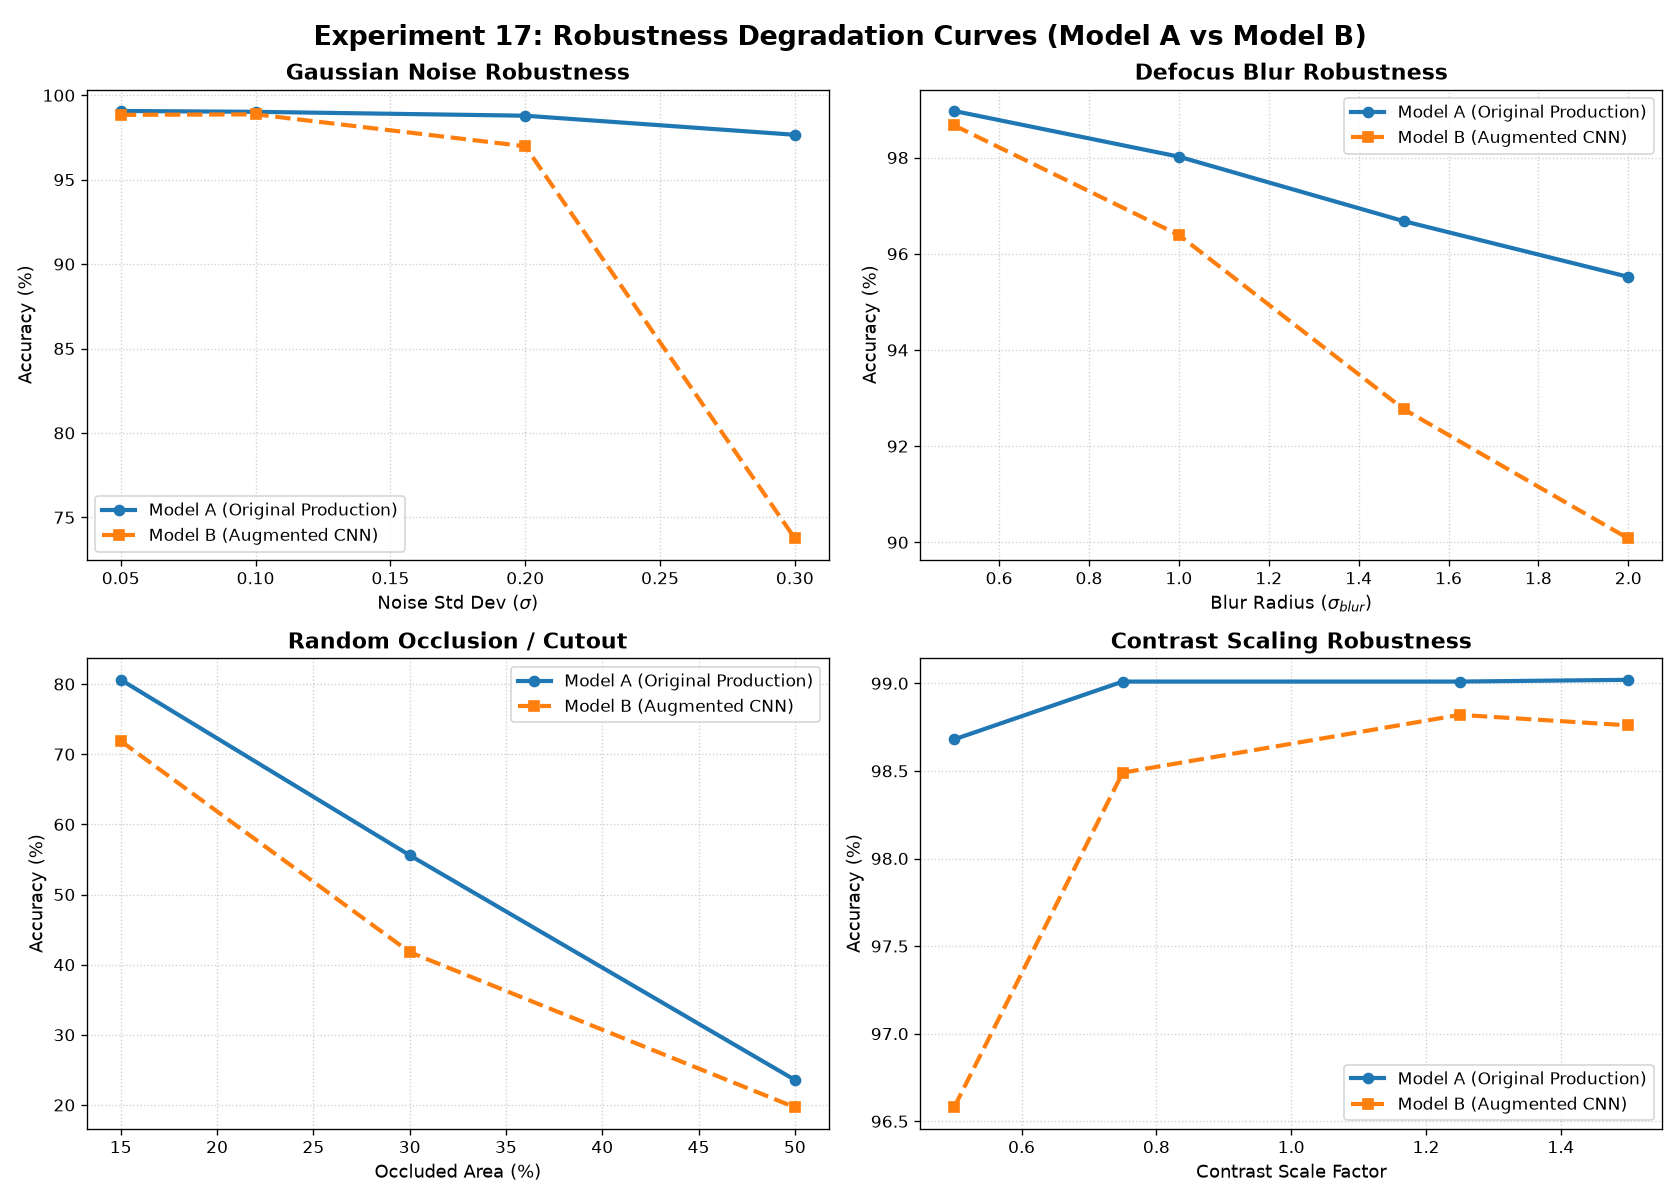

In [1]:
# Plot Robustness Degradation and Confidence Curves
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Experiment 17: Robustness Degradation Curves (Model A vs Model B)', fontsize=15, fontweight='bold')

axes[0, 0].plot(noise_sigmas, [r[0]*100 for r in noise_results_a], 'o-', label='Model A (Production)')
axes[0, 0].plot(noise_sigmas, [r[0]*100 for r in noise_results_b], 's--', label='Model B (Augmented)')
axes[0, 0].set_title('Gaussian Noise Robustness'); axes[0, 0].set_ylabel('Accuracy (%)'); axes[0, 0].grid(True, alpha=0.5); axes[0, 0].legend()

axes[0, 1].plot(blur_sigmas, [r[0]*100 for r in blur_results_a], 'o-', label='Model A (Production)')
axes[0, 1].plot(blur_sigmas, [r[0]*100 for r in blur_results_b], 's--', label='Model B (Augmented)')
axes[0, 1].set_title('Defocus Blur Robustness'); axes[0, 1].set_ylabel('Accuracy (%)'); axes[0, 1].grid(True, alpha=0.5); axes[0, 1].legend()

axes[1, 0].plot(cutout_configs, [r[0]*100 for r in cutout_results_a], 'o-', label='Model A (Production)')
axes[1, 0].plot(cutout_configs, [r[0]*100 for r in cutout_results_b], 's--', label='Model B (Augmented)')
axes[1, 0].set_title('Random Occlusion / Cutout'); axes[1, 0].set_ylabel('Accuracy (%)'); axes[1, 0].grid(True, alpha=0.5); axes[1, 0].legend()

axes[1, 1].plot(contrast_factors, [r[0]*100 for r in contrast_results_a], 'o-', label='Model A (Production)')
axes[1, 1].plot(contrast_factors, [r[0]*100 for r in contrast_results_b], 's--', label='Model B (Augmented)')
axes[1, 1].set_title('Contrast Shift Robustness'); axes[1, 1].set_ylabel('Accuracy (%)'); axes[1, 1].grid(True, alpha=0.5); axes[1, 1].legend()

plt.tight_layout()
plt.show()

---
## 9. Track B — CIFAR-10 Transfer Learning Historical Reference

> [!IMPORTANT]
> **Formal Audit Note on Track B Artifacts:**
> Robustness stress testing for the CIFAR-10 models was not performed because the trained checkpoints were not persisted from the Colab runtimes of Experiments 15 and 16.

### Historical Benchmark Results (Clean Test Set):
| Model Candidate | Trainable Parameters | Clean Test Accuracy | Test Errors (out of 10,000) | Notes |
|:---|---:|---:|---:|:---|
| **Frozen ResNet-18** (Exp 15 Reference) | 5,130 | **64.59%** | 3,541 | Pretrained backbone 100% frozen |
| **CNN From Scratch** (Exp 15 Reference) | 620,810 | **74.52%** | 2,548 | Trained 100% on CIFAR-10 |
| **Layer4 + Head Fine-Tuning** (Exp 16) | 8,398,858 | **77.67%** | 2,233 | Unfrozen Layer4 + Head (LR: 1e-5 / 1e-3) |
| **Full ResNet-18 Fine-Tuning** (Exp 16) | 11,181,642 | **84.68%** | 1,532 | Unfrozen all layers (LR: 1e-5 / 1e-3) |

### Architectural & Curricular Role:
The CIFAR-10 transfer learning track is an **educational exploration** designed to teach feature reuse, representational hierarchies, resolution mismatch, and discriminative fine-tuning. It is not an alternative candidate for the live handwriting recognizer.

---
## 10. Final Model Selection Matrix & Production Recommendation

### Multi-Criteria Robustness Comparison (Track A):
| Evaluation Dimension | Model A (Production CNN) | Model B (Augmented CNN) | Superior Candidate | Empirical Rationale |
|:---|:---:|:---:|:---:|:---|
| **Clean MNIST Accuracy** | **99.07%** (93 errors) | 98.83% (117 errors) | **Model A** | +0.24% higher accuracy (24 fewer errors) |
| **Gaussian Noise Robustness** | **97.66%** at $\sigma=0.30$ | 73.75% at $\sigma=0.30$ | **Model A** | Model B collapses under heavy noise (+2,391 errors) |
| **Defocus Blur Robustness** | **95.52%** at $\sigma=2.0$ | 90.08% at $\sigma=2.0$ | **Model A** | Model A retains higher accuracy at all blur levels |
| **Occlusion / Cutout Robustness** | **55.60%** at 30% cutout | 41.79% at 30% cutout | **Model A** | Model A handles partial stroke loss significantly better |
| **Contrast Shift Robustness** | **98.68%** at $0.50\times$ | 96.58% at $0.50\times$ | **Model A** | Model A maintains high recognition on faint strokes |
| **Real-World Handwriting Accuracy** | **100.0%** (35 / 35) | **100.0%** (35 / 35) | **Tie** | Both models achieve 100% when coupled with Phase 10 |
| **Real-World Mean Confidence** | **98.48%** | 95.64% | **Model A** | Model B displays unnecessary hesitation |
| **Inference Latency (CPU P50)** | **0.376 ms** | 0.374 ms | **Tie** | Identical 421,642 parameter architecture |
| **Throughput (CPU)** | **7,999 samples/s** | 7,262 samples/s | **Tie** | Virtually identical execution speeds |

### Definitive Production Recommendation:
**DECISION: RETAIN ORIGINAL PRODUCTION MODEL (`cnn_mnist.pt`)**

1. **No Automatic Selection:** Training with affine data augmentation (rotations, translations) did **not** confer generalized robustness against real-world corruptions. In fact, Model B proved significantly **more fragile** to sensor noise, optical blur, and partial stroke occlusions.
2. **Covariate Shift is Solved Upstream:** As established in Phase 10, handwriting canvas variance (scale, margins, off-center placement) is completely solved by geometric preprocessing (bounding-box extraction and center-of-mass centering).
3. **Zero Regressions:** Retaining `backend/models/cnn_mnist.pt` preserves the highest benchmark accuracy (99.07%), superior noise/occlusion immunity, and maximum production stability.